In [35]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

In [36]:
# ===================== 1. Загрузка данных =====================
TRAIN_PATH = "/content/train.csv"
TEST_PATH = "/content/test_features.csv"
OUT_PATH = "/content/outputs/task1_predictions.csv"

df = pd.read_csv(TRAIN_PATH)
df_test = pd.read_csv(TEST_PATH)

print(f"Train: {df.shape}, Test: {df_test.shape}")
df.head()

Train: (800, 19), Test: (200, 18)


,patient_id,Возраст,Пол_мужской,ИМТ,Окружность_талии_см,САД_мм_рт_ст,ДАД_мм_рт_ст,Пульсовое_давление,Глюкоза_натощак_ммоль_л,HbA1c_%,ЛПНП_ммоль_л,ЛПВП_ммоль_л,Триглицериды_ммоль_л,СКФ_мл_мин,Курение,Физическая_активность_мин_нед,prediction,Статус_глюкозы,Доклинический_риск
0,1,41,1,24.24,81.04,113.19,62.54,50.65,4.595,4.65,NaN,NaN,1.379,115.52,0,165.8,0,0,0
1,4,53,0,19.84,73.44,119.75,71.59,48.15,4.431,5.08,2.268,2.022,1.467,93.39,0,248.1,0,0,0
2,5,53,1,24.28,82.06,127.07,70.34,56.73,4.997,5.04,2.459,1.325,0.967,88.41,0,230.5,0,0,0
3,6,60,1,25.19,91.89,116.98,82.00,34.98,5.491,5.00,3.700,0.722,1.505,91.06,1,132.5,1,0,0
4,7,59,1,24.45,84.07,129.12,82.70,46.42,6.456,4.80,3.960,1.406,2.274,89.74,1,177.4,1,2,0


In [46]:
# Целевая переменная — prediction, patient_id — идентификатор (не признак)
TARGET = "prediction"
ID_COL = "patient_id"
feature_cols = [c for c in df.columns if c not in (ID_COL, TARGET)]

X = df[feature_cols].values.astype(np.float32)
y = df[TARGET].values.astype(np.float32).reshape(-1, 1)
X_submit = df_test[feature_cols].values.astype(np.float32)

print(f"Признаков: {X.shape[1]}, Объектов: {X.shape[0]}")
print("Баланс классов:", df[TARGET].value_counts().to_dict())
print("\nПропуски в train:")
print(df[feature_cols].isna().sum()[lambda s: s > 0])

Признаков: 17, Объектов: 800
Баланс классов: {0: 655, 1: 145}

Пропуски в train:
ЛПНП_ммоль_л            35
ЛПВП_ммоль_л            45
Триглицериды_ммоль_л    46
СКФ_мл_мин              47
dtype: int64


In [47]:
# ===================== 2. Разбиение на train/val =====================
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

In [48]:
# ===================== 3. Заполнение пропусков и нормализация =====================
def fit_preprocess(X_fit):
    medians = np.nanmedian(X_fit, axis=0)
    X_filled = np.where(np.isnan(X_fit), medians, X_fit)
    scaler = StandardScaler().fit(X_filled)
    return medians, scaler

def apply_preprocess(X_in, medians, scaler):
    X_filled = np.where(np.isnan(X_in), medians, X_in)
    return scaler.transform(X_filled).astype(np.float32)

medians, scaler = fit_preprocess(X_train)
X_train_s = apply_preprocess(X_train, medians, scaler)
X_val_s = apply_preprocess(X_val, medians, scaler)

In [49]:
# ===================== 4. Тензоры и DataLoader =====================
batch_size = 32
train_loader = DataLoader(TensorDataset(torch.tensor(X_train_s), torch.tensor(y_train)),
                          batch_size=batch_size, shuffle=True)
val_loader = DataLoader(TensorDataset(torch.tensor(X_val_s), torch.tensor(y_val)),
                        batch_size=batch_size, shuffle=False)

In [50]:
# ===================== 5. Определение модели FFN =====================
class PatientFFN(nn.Module):
  def __init__(self, input_dim):
    super().__init__()
    self.fc1 = nn.Linear(input_dim, 64)
    self.fc2 = nn.Linear(64, 32)
    self.fc3 = nn.Linear(32, 1)  # один выход (logit) для бинарной классификации
    self.relu = nn.ReLU()
    self.dropout = nn.Dropout(0.3)

  def forward(self, x):
    x = self.relu(self.fc1(x))
    x = self.dropout(x)
    x = self.relu(self.fc2(x))
    x = self.dropout(x)
    x = self.fc3(x)  # линейный выход (logits)
    return x

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [51]:
# ===================== 6. Функция потерь, оптимизатор, цикл обучения =====================
def make_criterion(y_fit):
    pos_weight = torch.tensor([(y_fit == 0).sum() / (y_fit == 1).sum()], dtype=torch.float32)
    return nn.BCEWithLogitsLoss(pos_weight=pos_weight.to(device))

def train_model(train_loader, input_dim, criterion, epochs, val_loader=None):
    torch.manual_seed(SEED)
    model = PatientFFN(input_dim).to(device)
    optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
    train_losses, val_losses = [], []

    for epoch in range(epochs):
        # --- Train ---
        model.train()
        running_loss = 0.0
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            loss = criterion(model(X_batch), y_batch)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * X_batch.size(0)
        train_losses.append(running_loss / len(train_loader.dataset))

        # --- Validation ---
        if val_loader is not None:
            model.eval()
            val_loss = 0.0
            with torch.no_grad():
                for X_batch, y_batch in val_loader:
                    X_batch, y_batch = X_batch.to(device), y_batch.to(device)
                    val_loss += criterion(model(X_batch), y_batch).item() * X_batch.size(0)
            val_losses.append(val_loss / len(val_loader.dataset))

            if (epoch + 1) % 10 == 0:
                print(f"Epoch {epoch+1}/{epochs} — Train Loss: {train_losses[-1]:.4f}, Val Loss: {val_losses[-1]:.4f}")

    return model, train_losses, val_losses

def predict_proba(model, X_np):
    model.eval()
    with torch.no_grad():
        logits = model(torch.tensor(X_np).to(device))
        return torch.sigmoid(logits).cpu().numpy().flatten()

epochs = 40
criterion = make_criterion(y_train)
model, train_losses, val_losses = train_model(train_loader, X_train_s.shape[1], criterion, epochs, val_loader)

Epoch 10/40 — Train Loss: 0.3225, Val Loss: 0.3158
Epoch 20/40 — Train Loss: 0.2221, Val Loss: 0.3211
Epoch 30/40 — Train Loss: 0.1392, Val Loss: 0.3388
Epoch 40/40 — Train Loss: 0.1024, Val Loss: 0.3566


In [52]:
# ===================== 7. Метрики на валидации =====================
y_val_prob = predict_proba(model, X_val_s)
y_val_true = y_val.flatten()
y_val_pred = (y_val_prob >= 0.5).astype(int)

print("=" * 50)
print("Оценка на валидационной выборке:")
print("=" * 50)
print(f"Accuracy:  {accuracy_score(y_val_true, y_val_pred):.4f}")
print(f"Precision: {precision_score(y_val_true, y_val_pred):.4f}")
print(f"Recall:    {recall_score(y_val_true, y_val_pred):.4f}")
print(f"F1-score:  {f1_score(y_val_true, y_val_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_val_true, y_val_prob):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_val_true, y_val_pred))

Оценка на валидационной выборке:
Accuracy:  0.9437
Precision: 0.8333
Recall:    0.8621
F1-score:  0.8475
ROC-AUC:   0.9845

Confusion Matrix:
[[126   5]
 [  4  25]]


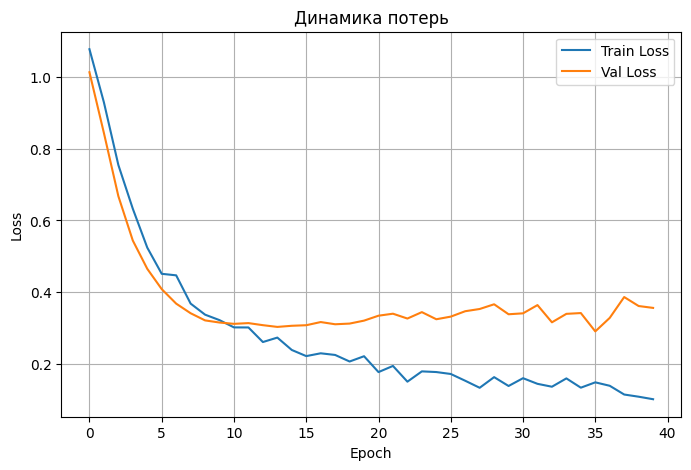

In [53]:
# ===================== 8. График потерь =====================
plt.figure(figsize=(8, 5))
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Динамика потерь')
plt.legend()
plt.grid(True)
plt.show()

In [54]:
# ===================== 9. Финальное обучение на всём train =====================
medians_full, scaler_full = fit_preprocess(X)
X_full_s = apply_preprocess(X, medians_full, scaler_full)
X_submit_s = apply_preprocess(X_submit, medians_full, scaler_full)

full_loader = DataLoader(TensorDataset(torch.tensor(X_full_s), torch.tensor(y)),
                         batch_size=batch_size, shuffle=True)
final_model, _, _ = train_model(full_loader, X_full_s.shape[1], make_criterion(y), epochs)

In [55]:
# ===================== 10. Предсказания для test_features.csv =====================
test_prob = predict_proba(final_model, X_submit_s)
submission = pd.DataFrame({
    "patient_id": df_test[ID_COL].values,
    "prediction": (test_prob >= 0.5).astype(int),
})

assert len(submission) == len(df_test)
assert (submission["patient_id"].values == df_test[ID_COL].values).all()
assert submission.notna().all().all()

os.makedirs(os.path.dirname(OUT_PATH), exist_ok=True)
submission.to_csv(OUT_PATH, index=False)
print(f"Сохранено: {OUT_PATH}")
print(submission["prediction"].value_counts())
submission.head()

Сохранено: /content/outputs/task1_predictions.csv
prediction
0    161
1     39
Name: count, dtype: int64


,patient_id,prediction
0,2,0
1,3,1
2,8,0
3,18,0
4,19,0


In [29]:
from google.colab import files
files.download(OUT_PATH)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>